In [13]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
import math
import pyperclip
import os
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.stats import norm

In [86]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/background"

# folder where all results (CSV + plots) will be saved
results_folder = "results/background_deg1"

In [87]:
# ── CONFIGURATION ─────────────────────────────────────────────────────────────
csv_folder   = absorption_data_folder                          # CSV input folder
plots_folder = os.path.join(results_folder, "fit_plots")      # fit plot output folder
output_file  = os.path.join(results_folder, "background_results_deg1.csv")  # results CSV
save_plots   = True                                            # save fit plots
sides        = ["1", "2", "3", "4"]                           # sides to fit
degree = 1 # i do not like this, but degree = 1 gets weird/inconsistent results
# ──────────────────────────────────────────────────────────────────────────────

#  fit equation
def gaussian(x, x0, A, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


# auto-detect heights from all CSV files in csv_folder
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith(".csv")])
heights   = [os.path.splitext(f)[0] for f in csv_files]

# create output directories if they don't exist
if save_plots:
    os.makedirs(plots_folder, exist_ok=True)
os.makedirs(os.path.dirname(output_file) or ".", exist_ok=True)

print(f"Found {len(heights)} CSV files: {heights}")

results = []  # list of dicts, one per height

for height in heights:
    filepath = os.path.join(csv_folder, f"{height}.csv")
    row = {"height": height}

    for side in sides:
        try:
            # ── Cell 4 logic ────────────────────────────────────────────────────
            data = pd.read_csv(filepath)

            t_min, t_max = -np.inf, np.inf
            if side == "n":
                t_min, t_max = -np.inf, np.inf
            elif side == "1":
                t_min, t_max = -0.003, -0.00105
            elif side == "2":
                t_min, t_max = -0.0009, 0.001
            elif side == "3":
                t_min, t_max = 0.0011, 0.003
            elif side == "4":
                t_min, t_max = 0.0031, 0.005

            data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
            t   = data_filtered['Time(s)']
            CH2 = data_filtered["CH2(V)"]

            # ── Cell 5 logic ────────────────────────────────────────────────────
            #filter data to not include the peaks 
            if side == "1":
                t_remove_min, t_remove_max = -0.0023, -0.00145
            elif side =="2":
                t_remove_min, t_remove_max = -0.0005, 0.00025
            elif side =="3":
                t_remove_min, t_remove_max = 0.00175, 0.00275
            elif side == "4":
                t_remove_min, t_remove_max = 0.0035, 0.0045
    
            data_subtrac_ramp = data_filtered[
                (data_filtered['Time(s)'] < t_remove_min) |
                (data_filtered['Time(s)'] > t_remove_max)
            ]
            t_ramp   = data_subtrac_ramp['Time(s)']
            CH2_ramp = data_subtrac_ramp["CH2(V)"]

            coeffs = np.polyfit(t_ramp, CH2_ramp, deg=degree)
            ramp   = np.polyval(coeffs, t)

            resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
            dof_r   = len(t_ramp) - 3
            sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

            Rb_spectrum = -(CH2 - ramp)

            # ── Cell 6 logic ────────────────────────────────────────────────────
            if side == "1":
                dx_guess = -0.00185
            elif side == "2":
                dx_guess = -0.0002
            elif side == "3":
                dx_guess = 0.00225
            elif side == "4":
                dx_guess = 0.0039

            H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
            p0 = [dx_guess,H_guess, 1.0e-3, 0.0]   # x0, A, sigma, offset
            lb = [-np.inf,  0, 1e-12,  -np.inf]
            ub = [np.inf,  np.inf,   9.5e-3,  np.inf]


            popt, pcov = curve_fit(
                gaussian, t, Rb_spectrum,
                p0=p0, sigma=sigma_y, absolute_sigma=True, method="trf", maxfev=1000
            )

            dx, scale, sigma, offset = popt
            edx, escale, esigma, eoffset = np.sqrt(np.diag(pcov))

            # replace NaN with 0 if fit converged but parameters are invalid
            escale = 0 if np.isnan(escale) else escale

            # save fit plot
            if save_plots:
                y_fit = gaussian(t, *popt)
                fig, ax = plt.subplots()
                ax.plot(t, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
                ax.plot(t, y_fit, label="fit", color="blue")
                ax.set_xlabel("Relative Laser Detuning, relative F=3-->4 (A.U.)")
                ax.set_ylabel("Relative Voltage Changes (A.U.)")
                ax.set_title(filepath)
                ax.legend(loc='best')
                fig.savefig(os.path.join(plots_folder, f"{height}_side{side}_fit.png"), dpi=100)
                plt.close(fig)

            row[f"Scale{side}"]  = 0 if np.isnan(scale)  else abs(gaussian(dx, *popt))
            row[f"eScale{side}"] = escale
            #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")

        except Exception as e:
            print(f"FAILED: {filepath} side={side} → {e}")
            row[f"Scale{side}"]  = 0
            row[f"eScale{side}"] = 0

    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv(output_file, index=False)
print(f"\nSaved → {output_file}")
df_out

Found 8 CSV files: ['200', '300', '400', '500', '600', '700', '800', '900']

Saved → results/background_deg1\background_results_deg1.csv


,height,Scale1,eScale1,Scale2,eScale2,Scale3,eScale3,Scale4,eScale4
0,200,0.002025,0.001192,0.002869,1444.747637,0.002297,2832.391550,0.003010,1875.642260
1,300,0.001739,0.000186,0.002711,2439.325837,0.001973,2238.335252,0.003871,0.002049
2,400,0.001162,0.000035,0.006949,5438.528126,0.005520,0.000027,0.007981,0.000108
3,500,0.003079,0.000349,0.002362,2148.817408,0.002128,1765.913469,0.004956,0.000040
4,600,0.004758,0.000042,0.001642,0.000158,0.000604,0.000065,0.001978,0.000115
5,700,0.000960,0.000029,0.005026,4334.566897,0.000479,0.000025,0.005101,0.000331
6,800,0.001157,1181.929115,0.002822,0.000017,0.000050,1457.845506,0.046668,0.111437
7,900,0.002797,0.000063,0.007739,4234.871171,0.002496,4082.753372,0.008754,3785.594430


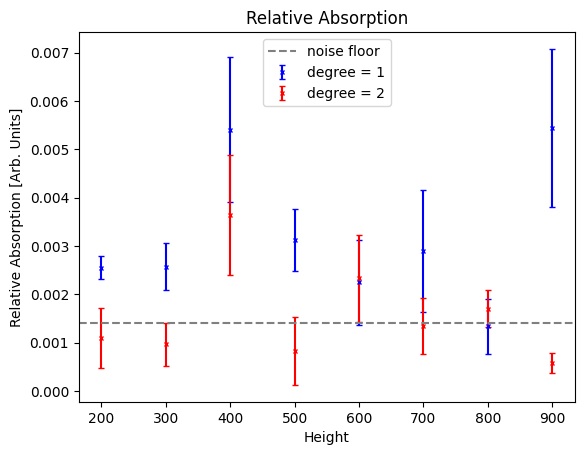

In [100]:
filepath3 = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\results\background_deg1\background_results_deg1.csv"

df = pd.read_csv(filepath3)

x = df['height'].to_numpy()
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_mean = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

plt.errorbar(x, y_mean, yerr=y_err, fmt='x', markersize=3, linestyle='None', capsize=2, c="blue",label ="degree = 1")
plt.title("Relative Absorption")
plt.xlabel("Height")
plt.ylabel("Relative Absorption [Arb. Units]")

filepath3 = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\results\background_deg2\background_results_deg2.csv"

df = pd.read_csv(filepath3)

x = df['height'].to_numpy()
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_mean = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

plt.errorbar(x, y_mean, yerr=y_err, fmt='x', markersize=3, linestyle='None', capsize=2, c="red",label ="degree = 2")
plt.axhline(1.414e-3, color="gray", linestyle ='--',label ='noise floor')
plt.title("Relative Absorption")
plt.xlabel("Height")
plt.ylabel("Relative Absorption [Arb. Units]")
plt.legend()
plt.show()